<div style="background:linear-gradient(135deg,#0f172a 0%,#14532d 55%,#1baf7a 100%);padding:34px 36px;border-radius:14px;color:#ffffff;font-family:Helvetica,Arial,sans-serif">
  <div style="font-size:13px;letter-spacing:2px;text-transform:uppercase;opacity:.8">Den Haag in Cijfers · Geographic analysis · Case study</div>
  <div style="font-size:34px;font-weight:700;margin:10px 0 6px">🏠 Do Richer Neighbourhoods Live in Greener Homes?</div>
  <div style="font-size:16px;opacity:.9">Household income, energy labels and neighbourhood types across the 114 neighbourhoods of The Hague</div>
  <div style="margin-top:18px;font-size:14px">
    <span style="background:rgba(255,255,255,.16);padding:5px 12px;border-radius:20px;margin-right:6px">👤 Mihail Deligrozev</span>
    <span style="background:rgba(255,255,255,.16);padding:5px 12px;border-radius:20px;margin-right:6px">🐍 geopandas · scikit-learn · SciPy · matplotlib</span>
    <span style="background:rgba(255,255,255,.16);padding:5px 12px;border-radius:20px">🧩 Spatial analysis + K-means</span>
  </div>
</div>

## 🧭 Executive summary


<table style="width:100%;border-collapse:separate;border-spacing:10px 0">
<tr>
<td style="background:#eaf3fd;border-radius:10px;padding:14px;vertical-align:top;width:25%"><div style="font-size:28px;font-weight:700;color:#2a78d6">−0.14</div><div style="color:#333">Rank correlation of income with the share of A-label homes, all neighbourhoods (n = 106, p = 0.16)</div></td>
<td style="background:#fdf0ea;border-radius:10px;padding:14px;vertical-align:top;width:25%"><div style="font-size:28px;font-weight:700;color:#eb6834">+0.47</div><div style="color:#333">Rank correlation of income with the share of E–G homes outside the new-build district (n = 91, p &lt; 0.001)</div></td>
<td style="background:#fdf0ea;border-radius:10px;padding:14px;vertical-align:top;width:25%"><div style="font-size:28px;font-weight:700;color:#eb6834">71% vs 40%</div><div style="color:#333">Median share of E–G homes in high-income neighbourhoods vs the rest</div></td>
<td style="background:#eaf3fd;border-radius:10px;padding:14px;vertical-align:top;width:25%"><div style="font-size:28px;font-weight:700;color:#2a78d6">51% vs 6%</div><div style="color:#333">Median share of A-label homes in the new-build district vs the rest of the city</div></td>
</tr></table>

**Question.** Do neighbourhoods in The Hague with higher household incomes have more energy-efficient homes?

**Answer: no, and in the older city it is the other way round.** Across all 106 neighbourhoods with data, income has no clear link with the share of A-label homes. That near-zero result hides two opposite patterns:

* **Outside the new-build district**, richer neighbourhoods have clearly *worse* labels. The wealthy villa areas along the dunes (Duttendel, Marlot, Nassaubuurt, Vogelwijk) have 86–94% of homes at E, F or G.
* **The best labels are in Leidschenveen-Ypenburg**, built after 1995, where incomes are close to the city average. Labels follow the **age of the housing**, not the income of the people living in it.

The high-income quarter of neighbourhoods is worse on all three label measures (Mann-Whitney p = 0.002 to 0.022). Income and labels are both strongly clustered on the map (Moran's I ≈ 0.6), so wealthy old housing and new energy-efficient housing sit in separate parts of the city.

**Part II, neighbourhood types.** K-means on the label mix finds **five stable types**: Mostly A, Mostly A and B, Mixed (centred on C), E-dominated and G-dominated. The two poorest types cover half of all neighbourhoods. The types form clear zones on the map (50% of neighbouring pairs share a type, against 26% by chance), and the two A types have middle incomes, while 13 of the 27 high-income neighbourhoods are in the G-dominated type.


*Combines Assignments 2 (Geographic Visualisation) and 3 (Prediction/Inference) of EPA-1316 Introduction to Urban Data Science, TU Delft. Rebuilt as one standalone case study on the same Den Haag in Cijfers data and neighbourhood boundaries: Part I tests the income hypothesis, Part II groups neighbourhoods into types with K-means.*

### 📑 Contents

| # | Section | What happens |
|---|---|---|
| | **Part I · Income and energy labels** | |
| 1 | [⚙️ Setup](#setup) | Libraries, chart style, helper functions |
| 2 | [📥 Load and profile](#load) | Read the label/income table and the boundaries, check the join |
| 3 | [🧹 Clean and define the measures](#clean) | Label shares, an average-label score, "high income", small-count filter |
| 4 | [🗺️ Where are the good labels?](#maps) | Label mix per neighbourhood, side-by-side maps, a bivariate map |
| 5 | [📊 Testing the hypothesis](#tests) | Rank correlation, income quartiles, high-income vs the rest |
| 6 | [🏗️ The building-age effect](#age) | Old city vs the new-build districts |
| 7 | [🧲 Spatial clustering](#moran) | Moran's I: do similar neighbourhoods sit together? |
| 8 | [🏅 Five neighbourhoods](#five) | The assignment's list, plus five retrofit candidates |
| | **Part II · Neighbourhood types (K-means)** | |
| 9 | [🧩 Features and the number of clusters](#kchoice) | Label-share features; choosing k with elbow, silhouette and stability |
| 10 | [🗂️ The five neighbourhood types](#types) | Named cluster profiles and where they are |
| 11 | [🧪 How good are the clusters?](#evaluate) | Silhouette per neighbourhood, dominant-label check, spatial coherence |
| 12 | [💶 Do the types differ in income?](#typeincome) | Links the types back to the Part I hypothesis |
| | **Wrap-up** | |
| 13 | [🏁 Findings and limitations](#findings) | Answers, caveats, what changed from the originals |
| 14 | [💾 Save outputs](#save) | Clean table with cluster types, GeoJSON and figures |

<a id="setup"></a>
## ⚙️ 1. Setup
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>All charts share one style, energy labels always use the familiar green-to-red label colours, and every chart is numbered and saved as a PNG so the findings can point back to <i>Figure N</i>. The helpers (map drawing, bootstrap intervals, neighbour weights, Moran's I) live here so the analysis cells stay short. Neighbour weights are built from shared boundary points with plain NumPy, so the notebook doesn't need PySAL.</div>

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter, PercentFormatter
from scipy.stats import spearmanr, mannwhitneyu

try:
    import geopandas as gpd
    import shapely
except ImportError:
    raise ImportError("Install geopandas first:  pip install geopandas  (it is pre-installed on Kaggle)")

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:,.2f}".format)

# 🎨 palette and chart style
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
INK, MUTED, GRID, SURFACE, NODATA = "#0b0b0b", "#52514e", "#e5e4df", "#fcfcfb", "#d9d8d3"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": .8,
    "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
    "legend.frameon": False, "lines.linewidth": 2, "hatch.color": "#9a9993",
})

# 🏷️ energy labels, best to worst, in the colours used on Dutch label certificates
LABELS = ["A++", "A+", "A", "B", "C", "D", "E", "F", "G"]
LABEL_COLORS = ["#00843d", "#2aa13c", "#55b947", "#bed630", "#ffdd00", "#fdb913", "#f37021", "#ed1c24", "#b5121b"]
LABEL_SCORE = dict(zip(LABELS, range(9, 0, -1)))          # A++ = 9 ... G = 1

# 📁 paths: works locally (./data) and on Kaggle (/kaggle/input/...)
def find_file(*patterns):
    for pattern in patterns:
        for base in [Path("data"), Path("."), Path("/kaggle/input")]:
            hits = sorted(base.rglob(pattern)) if base.exists() else []
            if hits:
                return hits[0]
    raise FileNotFoundError(patterns)

OUT_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path("output")
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 🖼️ numbered figures, saved as PNG
_FIG = {"n": 0}
def figure_title(fig, text, y=1.0):
    _FIG["n"] += 1
    fig.suptitle(f"Figure {_FIG['n']} · {text}", x=0.01, y=y, ha="left", fontsize=13, fontweight="bold", color=INK)
    return _FIG["n"]

def save(fig, name):
    fig.savefig(FIG_DIR / f"fig{_FIG['n']:02d}_{name}.png", dpi=150, bbox_inches="tight", facecolor=SURFACE)
    plt.show()

eur = FuncFormatter(lambda v, _: f"€{v/1000:,.0f}k")
pct = PercentFormatter(100, decimals=0)

# 🗺️ map helpers
def map_axis(ax):
    ax.set_axis_off()
    ax.set_aspect("equal")

def classed_colors(values, bins, cmap):
    """Colour each value by the class it falls in (bins = class edges); NaN -> no-data grey."""
    from matplotlib.colors import ListedColormap
    k = len(bins) - 1
    cm = ListedColormap(plt.get_cmap(cmap)(np.linspace(0.2, 0.95, k)))   # skip the near-white end
    cls = np.clip(np.digitize(values, bins[1:-1]), 0, len(bins) - 2)
    return [NODATA if pd.isna(v) else cm(c) for v, c in zip(values, cls)], cm

def choropleth(gdf, col, ax, cmap, k=5, fmt="{:.0f}", title=None, bins=None):
    """Quantile choropleth with a compact class legend; missing values hatched."""
    vals = gdf[col]
    bins = np.nanquantile(vals, np.linspace(0, 1, k + 1)) if bins is None else np.asarray(bins)
    colors, cm = classed_colors(vals, bins, cmap)
    gdf.plot(ax=ax, color=colors, edgecolor="white", linewidth=0.4)
    miss = gdf[vals.isna()]
    if len(miss):
        miss.plot(ax=ax, color=NODATA, edgecolor="white", linewidth=0.4, hatch="////")
    handles = [Patch(color=cm(i), label=f"{fmt.format(bins[i])} – {fmt.format(bins[i+1])}") for i in range(len(bins) - 1)]
    if len(miss):
        handles.append(Patch(facecolor=NODATA, hatch="////", edgecolor="#9a9993", label="no data"))
    ax.legend(handles=handles, loc="upper left", fontsize=8, title=title, title_fontsize=8, handlelength=1.2)
    map_axis(ax)

# 📐 statistics helpers
def fmt_p(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"

def spearman_ci(x, y, n_boot=2000, seed=42):
    """Spearman rho with a percentile bootstrap 95% CI."""
    x, y = np.asarray(x), np.asarray(y)
    rho, p = spearmanr(x, y)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(x), (n_boot, len(x)))
    boots = [spearmanr(x[i], y[i])[0] for i in idx]
    lo, hi = np.nanpercentile(boots, [2.5, 97.5])
    return rho, p, lo, hi

def queen_weights(gdf, decimals=7):
    """Row-standardised contiguity matrix: two areas are neighbours if they share a boundary point."""
    xy, idx = shapely.get_coordinates(gdf.geometry.to_numpy(), return_index=True)
    key = pd.Series(idx).groupby([np.round(xy[:, 0], decimals), np.round(xy[:, 1], decimals)]).unique()
    n = len(gdf)
    W = np.zeros((n, n))
    for ids in key:
        if len(ids) > 1:
            for i in ids:
                W[i, ids] = 1
    np.fill_diagonal(W, 0)
    return W / W.sum(1, keepdims=True).clip(min=1)

def morans_i(y, W, n_perm=999, seed=42):
    """Global Moran's I with a one-sided permutation p-value (clustering)."""
    z = np.asarray(y, float) - np.mean(y)
    I = len(z) / W.sum() * (z @ W @ z) / (z @ z)
    rng = np.random.default_rng(seed)
    sims = np.array([(lambda s: len(s) / W.sum() * (s @ W @ s) / (s @ s))(rng.permutation(z)) for _ in range(n_perm)])
    p = (1 + (sims >= I).sum()) / (n_perm + 1)
    return I, p, sims

print("✅ setup done · figures go to", FIG_DIR)

✅ setup done · figures go to output/figures


<a id="load"></a>
## 📥 2. Load and profile the data

Two inputs:

| File | Contents |
|---|---|
| `neighborhoods.csv` | Exported from **Den Haag in Cijfers**: number of homes per energy label (A++ to G) and the *average standardised disposable income of private households* per neighbourhood |
| `neighborhoods.json` (or `.shp`) | Boundaries of the 114 neighbourhoods (*buurten*), prepared for the course, in WGS 84 |

The **standardised disposable income** is household income after tax and transfers, corrected for household size and composition, so a single person and a family of four can be compared.
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>Before any analysis it is worth checking three things: that the columns are what their names say (the CSV lists label G <i>before</i> F), that every row is a real neighbourhood, and that every neighbourhood in the table finds its shape on the map. A silent mismatch in the join would drop areas from the maps without any error.</div>

In [2]:
CSV_FILE = find_file("neighborhoods.csv", "*neighborhoods*.csv")
raw = pd.read_csv(CSV_FILE, index_col=0)
raw.index.name = "neighbourhood"
print(f"{CSV_FILE.name}: {raw.shape[0]} rows × {raw.shape[1]} columns")
print("Columns:", [c.replace("Energielabel ", "") for c in raw.columns[:-1]], "+ income")
raw.tail(3)

neighborhoods.csv: 115 rows × 10 columns
Columns: ['A++', 'A+', 'A', 'B', 'C', 'D', 'E', 'G', 'F'] + income


,Energielabel A++,Energielabel A+,Energielabel A,Energielabel B,Energielabel C,Energielabel D,Energielabel E,Energielabel G,Energielabel F,Average standardised disposable income of private households
neighbourhood,,,,,,,,,,
120 De Vissen,1.00,0.00,"2,234.00",926.00,1.00,2.00,0.00,3.00,0.00,"34,700.00"
121 Rietbuurt,0.00,0.00,857.00,23.00,3.00,0.00,0.00,16.00,3.00,"34,200.00"
Unknown,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"-3,407.00"


<div style="background:#fdf0ea;border-left:5px solid #eb6834;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">⚠️ <b>Caution</b><br>The last row, <code>Unknown</code>, is not a neighbourhood: it holds homes that could not be placed in a <i>buurt</i>, and its income value (−3,407) is a balancing figure, not a real average. It is dropped below. Note also that the export puts <b>G before F</b>; the code reorders the columns by name, never by position.</div>

In [3]:
# 🗺️ boundaries: GeoJSON preferred (one file); shapefile as a fallback
GEO_FILE = find_file("neighborhoods.json", "*neighborhoods*.json", "neighborhoods.shp", "*neighborhoods*.shp")
geo_raw = gpd.read_file(GEO_FILE)
# the code+name column is 'neigb_cijfers' in the GeoJSON and 'neigb_cijf' in the shapefile (10-character limit)
key_col = [c for c in geo_raw.columns if c.startswith("neigb_cijf")][0]
geo_raw = geo_raw.rename(columns={key_col: "neighbourhood", "neighb_cbs": "name_cbs"})
print(f"{GEO_FILE.name}: {len(geo_raw)} shapes · CRS {geo_raw.crs}")

# 🔗 does every table row find a shape, and vice versa?
in_table = set(raw.index) - {"Unknown"}
in_map = set(geo_raw["neighbourhood"])
print(f"Table rows without a shape : {sorted(in_table - in_map) or 'none'}")
print(f"Shapes without a table row : {sorted(in_map - in_table) or 'none'}")
geo_raw.head(3)[["neighbourhood", "name_cbs"]]

neighborhoods.json: 114 shapes · CRS EPSG:4326
Table rows without a shape : none
Shapes without a table row : none


,neighbourhood,name_cbs
0,70 Oostduinen,Oostduinen
1,71 Belgisch Park,Belgisch Park
2,73 Westbroekpark,Westbroekpark


<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>All 114 neighbourhoods in the table match a shape on the map, with no leftovers on either side. The join key is the <i>code + name</i> field (for example <code>70 Oostduinen</code>), which matches the table index exactly. The table covers 261,797 homes with a registered energy label.</div>

<a id="clean"></a>
## 🧹 3. Clean the data and define the measures

**Measures used throughout**

| Measure | Definition |
|---|---|
| **% A-label or better** | Homes with label A++, A+ or A, as a share of all homes with a registered label |
| **% E–G** | Homes with label E, F or G, as a share of all labelled homes |
| **Average label score** | Mean of the labels on a 1–9 scale (G = 1, F = 2 … A = 7, A+ = 8, A++ = 9). One number that uses all nine classes, not just the two ends |
| **High income** | Above the 75th percentile of neighbourhood income in The Hague, as stated in the original hypothesis |
| **New-build district** | Leidschenveen-Ypenburg (neighbourhood codes 101–121): added to The Hague in 2002 and built mostly from the late 1990s onward |

**Hypothesis (H1).** Neighbourhoods with higher household income have a larger share of homes with good energy labels.
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>The original notebook grouped labels into three bands (high, medium, low). That is kept, but a single <b>average label score</b> is added, because a neighbourhood that moves from G to D is better off even though it never reaches the high band. The <b>new-build</b> flag is added because the age of the housing is the most likely confounder: new homes get good labels whoever lives in them.</div>

In [4]:
df = raw.drop(index="Unknown").copy()
df.columns = [c.replace("Energielabel ", "") for c in df.columns[:-1]] + ["income"]
df = df[LABELS + ["income"]]                      # reorder by name: A++ … G

df["labelled_homes"] = df[LABELS].sum(axis=1)
shares = df[LABELS].div(df["labelled_homes"], axis=0) * 100
df["pct_A_or_better"] = shares[["A++", "A+", "A"]].sum(axis=1)
df["pct_B_to_D"] = shares[["B", "C", "D"]].sum(axis=1)
df["pct_E_to_G"] = shares[["E", "F", "G"]].sum(axis=1)
df["label_score"] = (df[LABELS] * pd.Series(LABEL_SCORE)).sum(axis=1) / df["labelled_homes"]

df["code"] = df.index.str.split(" ").str[0].astype(int)
df["area"] = np.where(df["code"] >= 101, "New-build (Leidschenveen-Ypenburg)", "Rest of the city")

print(f"{len(df)} neighbourhoods · {df['labelled_homes'].sum():,.0f} homes with a registered label")
print(f"Income missing for {df['income'].isna().sum()} neighbourhoods")
df.sort_values("labelled_homes")[["labelled_homes", "income", "pct_A_or_better"]].head(8)

114 neighbourhoods · 261,797 homes with a registered label
Income missing for 8 neighbourhoods


,labelled_homes,income,pct_A_or_better
neighbourhood,,,
109 Tedingerbroek,0.00,NaN,0.00
70 Oostduinen,1.00,NaN,0.00
107 Vliegeniersbuurt,1.00,NaN,100.00
117 De Rivieren,8.00,NaN,0.00
116 Vlietzoom-Oost,33.00,NaN,3.03
110 De Reef,49.00,NaN,97.96
106 Vlietzoom-West,65.00,NaN,3.08
36 Zuiderpark,101.00,"19,600.00",0.00


<div style="background:#fdf0ea;border-left:5px solid #eb6834;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">⚠️ <b>Caution</b><br>Shares are unreliable when a neighbourhood has very few labelled homes: Vliegeniersbuurt has <b>one</b> labelled home, so it shows 100% A-label. The original top-5 could have been distorted by cases like this. From here on, a neighbourhood is analysed only if it has <b>at least 100 labelled homes and an income figure</b>. In practice the two rules exclude the same 8 areas, because Den Haag in Cijfers withholds income figures for areas with very few residents (Kerketuinen/Zichtenburg has 130 labelled homes but no income figure).</div>

In [5]:
MIN_HOMES = 100
df["in_analysis"] = (df["labelled_homes"] >= MIN_HOMES) & df["income"].notna()
HIGH_INCOME = df.loc[df["in_analysis"], "income"].quantile(0.75)
df["high_income"] = df["income"] > HIGH_INCOME

# 🔗 join to the boundaries and project to the Dutch national grid (RD New, metres) for mapping
nb = geo_raw.merge(df, left_on="neighbourhood", right_index=True, how="left").to_crs(28992)
an = df[df["in_analysis"]].copy()

print(f"In the analysis: {len(an)} of {len(df)} neighbourhoods "
      f"({an['labelled_homes'].sum() / df['labelled_homes'].sum():.1%} of labelled homes)")
print(f"High-income threshold (75th percentile): €{HIGH_INCOME:,.0f} → {an['high_income'].sum()} neighbourhoods")
print(f"New-build neighbourhoods in the analysis: {(an['area'] != 'Rest of the city').sum()}")

In the analysis: 106 of 114 neighbourhoods (99.9% of labelled homes)
High-income threshold (75th percentile): €35,575 → 27 neighbourhoods
New-build neighbourhoods in the analysis: 15


**What is left out, and where?**

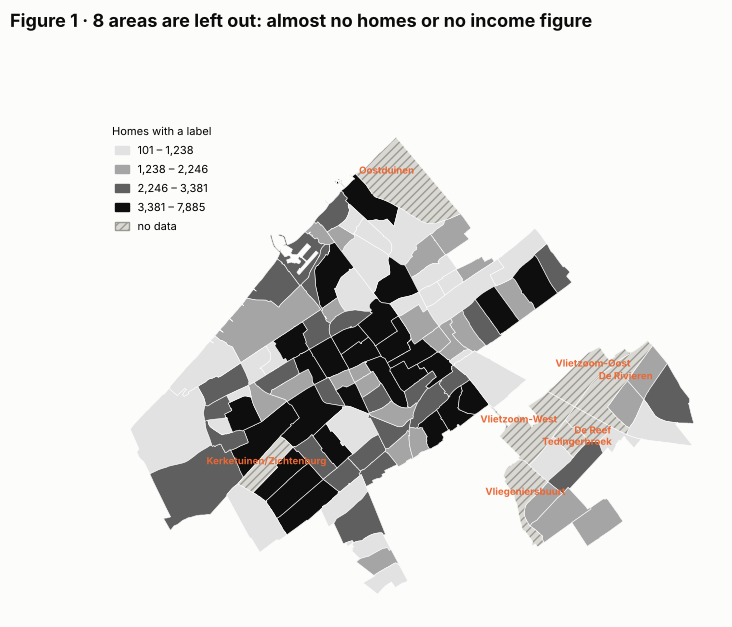

In [6]:
fig, ax = plt.subplots(figsize=(8, 7.5))
choropleth(nb.assign(labelled_homes=nb["labelled_homes"].where(nb["in_analysis"])), "labelled_homes", ax,
           "Greys", k=4, fmt="{:,.0f}", title="Homes with a label")
pts = nb[~nb["in_analysis"]].geometry.representative_point()
for (x, y), name in zip(zip(pts.x, pts.y), nb.loc[~nb["in_analysis"], "neighbourhood"]):
    ax.annotate(name.split(" ", 1)[1], (x, y), fontsize=7, color=ORANGE, ha="center", fontweight="bold")
figure_title(fig, f"{(~nb['in_analysis']).sum()} areas are left out: almost no homes or no income figure", y=0.97)
save(fig, "coverage_map")

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>The 8 excluded areas are almost empty: the Oostduinen dune reserve, a few industrial and edge zones in the new-build district, and the Kerketuinen business park. Together they hold only <b>0.1%</b> of labelled homes, so leaving them out does not change the picture for the city.</div>

<a id="maps"></a>
## 🗺️ 4. Where are the good labels?

**First, the full label mix.** Each thin bar is one neighbourhood, split into its nine label classes and sorted from best average label (left) to worst (right).
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>Grouping nine classes into three hides a lot. This chart shows every class for every neighbourhood at once, so it is easy to see whether the city is split into a few very good areas and many poor ones, or whether labels change gradually.</div>

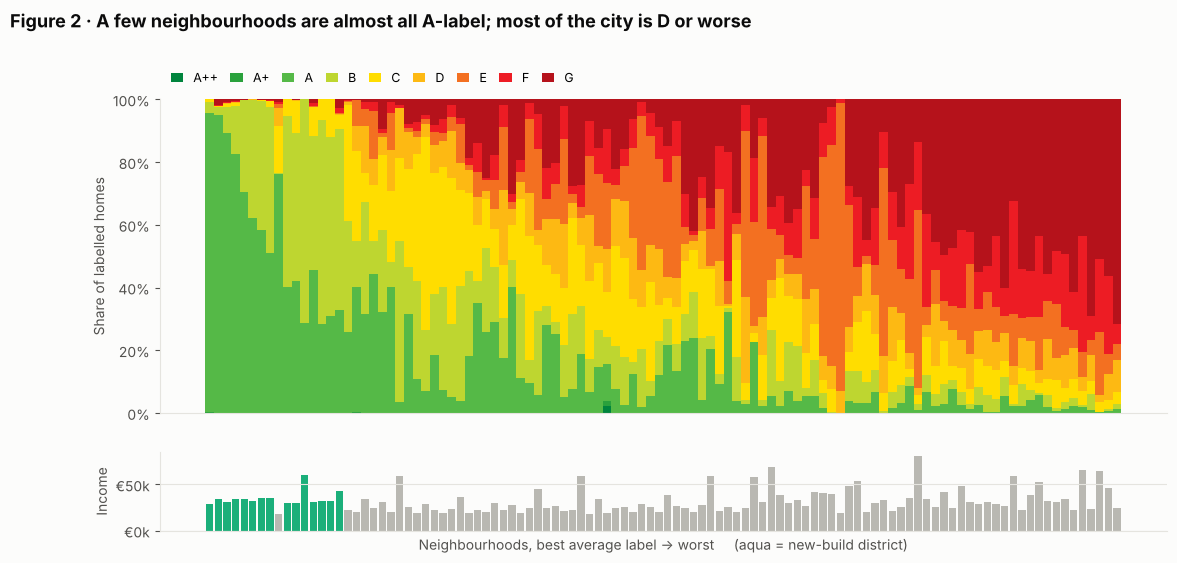

In [7]:
order = an.sort_values("label_score", ascending=False)
sh = order[LABELS].div(order["labelled_homes"], axis=0) * 100

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(13, 5.6), height_ratios=[4, 1], sharex=True)
bottom = np.zeros(len(sh))
x = np.arange(len(sh))
for lab, col in zip(LABELS, LABEL_COLORS):
    ax.bar(x, sh[lab], bottom=bottom, color=col, width=1.0, label=lab, linewidth=0)
    bottom += sh[lab].to_numpy()
ax.set_ylim(0, 100); ax.yaxis.set_major_formatter(pct); ax.grid(False)
ax.set_ylabel("Share of labelled homes")
ax.legend(ncol=9, loc="upper left", bbox_to_anchor=(0, 1.13), fontsize=9, handlelength=1, columnspacing=1)
new = (order["area"] != "Rest of the city").to_numpy()
ax2.bar(x, order["income"], color=np.where(new, AQUA, "#b9b8b2"), width=0.85)
ax2.yaxis.set_major_formatter(eur); ax2.set_ylabel("Income"); ax2.set_xticks([])
ax2.set_xlabel("Neighbourhoods, best average label → worst     (aqua = new-build district)")
figure_title(fig, "A few neighbourhoods are almost all A-label; most of the city is D or worse", y=1.04)
save(fig, "label_mix_strip")

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>Across the 106 neighbourhoods, <b>15% of labelled homes are A or better and 45% are E, F or G</b>; G alone is the most common label (24%). Only <b>9</b> neighbourhoods have more than half their homes at A or better, and 8 of them are in the new-build district (aqua bars, all on the far left). By contrast, <b>50</b> neighbourhoods have more than half their homes at E–G. The tallest income bars (bottom panel) are spread across the middle and right of the chart, not grouped on the left.</div>

**Side by side: income and the two ends of the label scale.**
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>Putting the maps next to each other with the same quantile classes makes it easy to compare patterns by eye. If the hypothesis were right, the darkest income areas (left) would match the darkest green areas (middle) and the lightest red areas (right).</div>

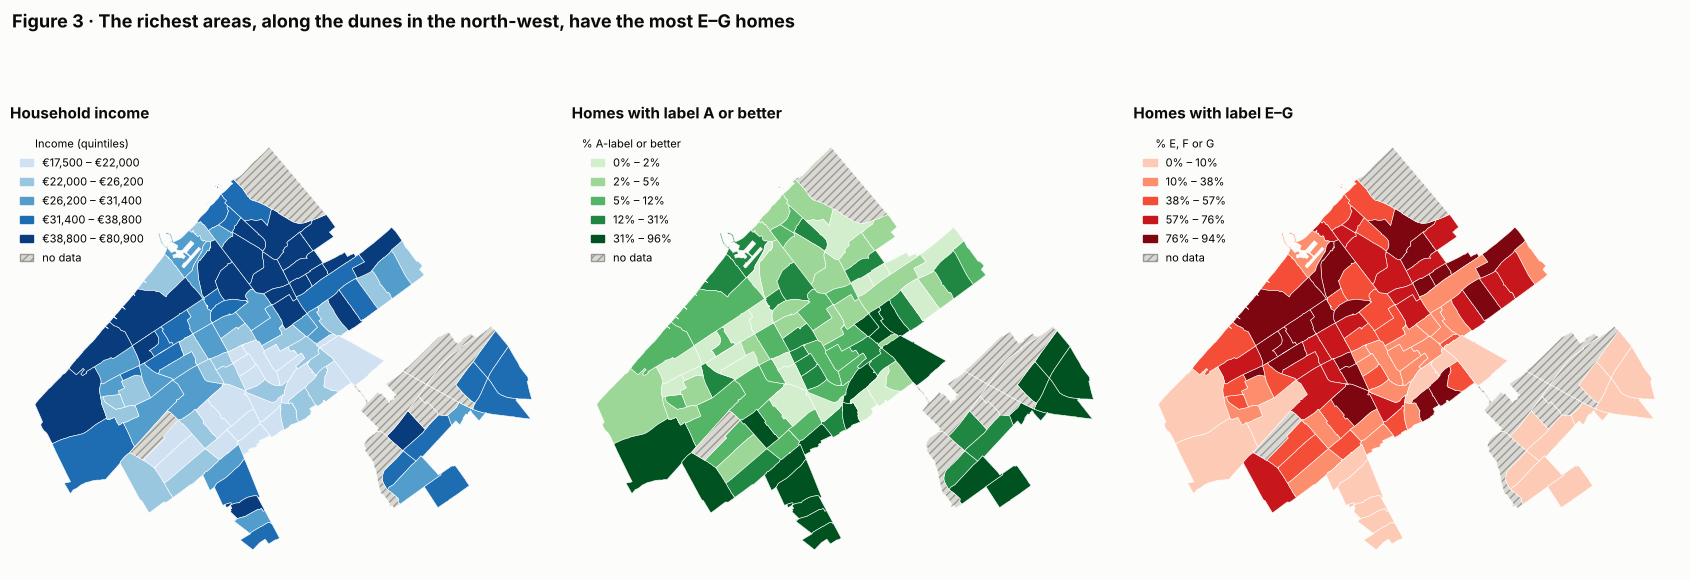

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6.4))
view = nb.copy()
for c in ["income", "pct_A_or_better", "pct_E_to_G"]:
    view[c] = view[c].where(view["in_analysis"])
choropleth(view, "income", axes[0], "Blues", fmt="€{:,.0f}", title="Income (quintiles)")
choropleth(view, "pct_A_or_better", axes[1], "Greens", fmt="{:.0f}%", title="% A-label or better")
choropleth(view, "pct_E_to_G", axes[2], "Reds", fmt="{:.0f}%", title="% E, F or G")
for ax, t in zip(axes, ["Household income", "Homes with label A or better", "Homes with label E–G"]):
    ax.set_title(t, fontsize=11)
figure_title(fig, "The richest areas, along the dunes in the north-west, have the most E–G homes", y=1.0)
fig.tight_layout()
save(fig, "maps_side_by_side")

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>The income map and the E–G map look alike: the dark-blue dune-side areas in the north-west (Benoordenhout, Statenkwartier, Archipelbuurt, Vogelwijk) are also dark red. The A-label map shows a different geography: the new-build district in the east, Hoge Veld and Kraayenstein in the south-west, and the redeveloped strip around Laakhaven and Binckhorst near the centre. This is the first sign that income and good labels are <i>not</i> found in the same places.</div>

**One map, two variables: a bivariate choropleth.**
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>Three separate maps still make the reader compare by eye. A bivariate map puts both variables in one colour: blue for income, pink for good labels. If income and good labels went together, most areas would be either light grey (low–low) or dark purple (high–high).</div>

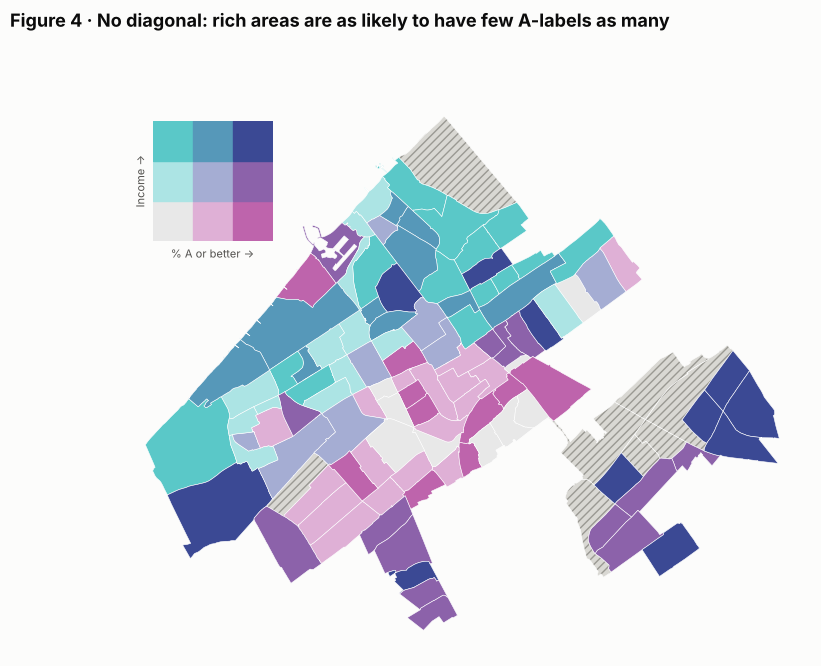

Neighbourhoods per cell (rows: income tercile low→high, cols: % A-or-better tercile low→high)
pct_A_or_better   0   1   2
income                     
0                 9  17  10
1                13   8  14
2                14  10  11


In [9]:
BIV = np.array([["#e8e8e8", "#dfb0d6", "#be64ac"],     # rows: income tercile low→high
                ["#ace4e4", "#a5add3", "#8c62aa"],     # cols: % A-or-better tercile low→high
                ["#5ac8c8", "#5698b9", "#3b4994"]])
view = nb[nb["in_analysis"]].copy()
inc_t = pd.qcut(view["income"], 3, labels=False)
lab_t = pd.qcut(view["pct_A_or_better"], 3, labels=False)
view["biv"] = [BIV[i, j] for i, j in zip(inc_t, lab_t)]

fig, ax = plt.subplots(figsize=(9, 8))
nb[~nb["in_analysis"]].plot(ax=ax, color=NODATA, edgecolor="white", linewidth=0.4, hatch="////")
view.plot(ax=ax, color=view["biv"].tolist(), edgecolor="white", linewidth=0.4)
map_axis(ax)

# 3×3 legend
lax = fig.add_axes([0.16, 0.66, 0.15, 0.15])
for i in range(3):
    for j in range(3):
        lax.add_patch(plt.Rectangle((j, i), 1, 1, color=BIV[i, j]))
lax.set_xlim(0, 3); lax.set_ylim(0, 3); lax.set_aspect("equal"); lax.grid(False)
lax.set_xticks([]); lax.set_yticks([])
lax.set_xlabel("% A or better →", fontsize=8); lax.set_ylabel("Income →", fontsize=8)
for s in lax.spines.values():
    s.set_visible(False)

counts = pd.crosstab(inc_t, lab_t)
figure_title(fig, "No diagonal: rich areas are as likely to have few A-labels as many", y=0.95)
save(fig, "bivariate_map")
print("Neighbourhoods per cell (rows: income tercile low→high, cols: % A-or-better tercile low→high)")
print(counts.to_string())

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>There is no diagonal. If the hypothesis held, most neighbourhoods would sit in the light-grey (low–low) and dark-indigo (high–high) corners. Instead, each of the nine combinations holds 8 to 17 neighbourhoods. The north-west is mostly <b>teal</b> (rich, few A-labels), the inner south is mostly <b>pink</b> (lower income, more A-labels after renewal), and the dark-indigo areas are mainly in the new-build district, the south-west edge and a few park-side areas in the north.</div>

<a id="tests"></a>
## 📊 5. Testing the hypothesis

**Income against the share of A-label homes.**
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>A scatter plot shows the whole relationship, not just a summary. The two groups are coloured separately because the maps already hinted that the new-build district behaves differently from the rest of the city. <b>Spearman's rank correlation</b> is used rather than Pearson because income is skewed (a few very rich areas) and label shares are bounded at 0 and 100%.</div>

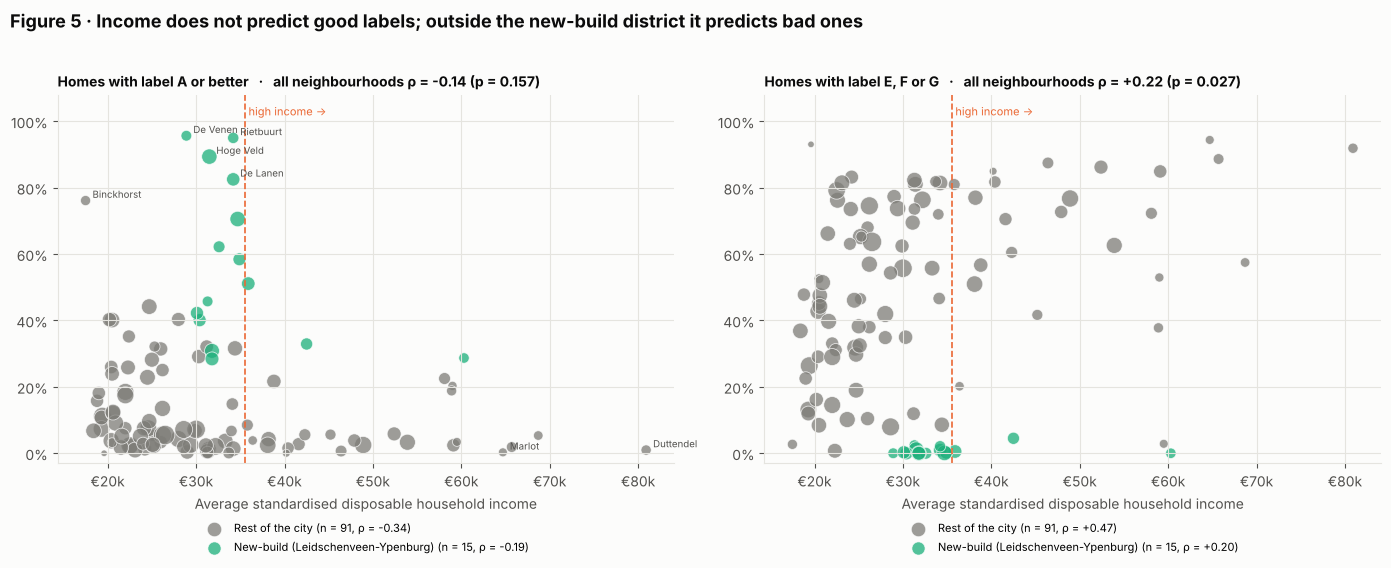

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), sharex=True)
for ax, (col, ylab) in zip(axes, [("pct_A_or_better", "Homes with label A or better"), ("pct_E_to_G", "Homes with label E, F or G")]):
    for area, color in [("Rest of the city", "#7d7c77"), ("New-build (Leidschenveen-Ypenburg)", AQUA)]:
        s = an[an["area"] == area]
        rho, p = spearmanr(s["income"], s[col])
        ax.scatter(s["income"], s[col], s=np.sqrt(s["labelled_homes"]) * 2.2, color=color, alpha=.75,
                   edgecolor="white", linewidth=.6, label=f"{area} (n = {len(s)}, ρ = {rho:+.2f})")
    rho, p = spearmanr(an["income"], an[col])
    ax.axvline(HIGH_INCOME, color=ORANGE, ls="--", lw=1.2)
    ax.text(HIGH_INCOME, 101, " high income →", color=ORANGE, fontsize=8, va="bottom")
    ax.set_ylim(-3, 108); ax.yaxis.set_major_formatter(pct); ax.xaxis.set_major_formatter(eur)
    ax.set_xlabel("Average standardised disposable household income")
    ax.set_title(f"{ylab}   ·   all neighbourhoods ρ = {rho:+.2f} (p = {fmt_p(p)})", fontsize=10)
    ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), fontsize=8, ncol=1)
for name in an.nlargest(5, "pct_A_or_better").index.tolist() + ["74 Duttendel", "68 Marlot"]:
    r = an.loc[name]
    axes[0].annotate(name.split(" ", 1)[1], (r["income"], r["pct_A_or_better"]), xytext=(5, 2),
                     textcoords="offset points", fontsize=7, color=MUTED)
figure_title(fig, "Income does not predict good labels; outside the new-build district it predicts bad ones", y=1.02)
fig.tight_layout()
save(fig, "scatter_income_labels")

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>Citywide, the link between income and A-label share is weak and not significant (ρ = −0.14, p = 0.16), which is what the original notebook found. The colours show why. The <b>new-build neighbourhoods</b> (aqua) sit high on the A-label axis at middle incomes. In the <b>rest of the city</b> (grey), the link is negative: richer areas have fewer A-label homes (ρ = −0.34) and many more E–G homes (ρ = +0.47). The richest neighbourhoods (Duttendel at €80,900, Marlot at €64,700) have almost no A-label homes.</div>

**The label mix by income quartile.**
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>Quartiles turn a cloud of points into four groups that are easy to compare. Showing the city with and without the new-build district side by side tests whether the result depends on the 15 new-build neighbourhoods.</div>

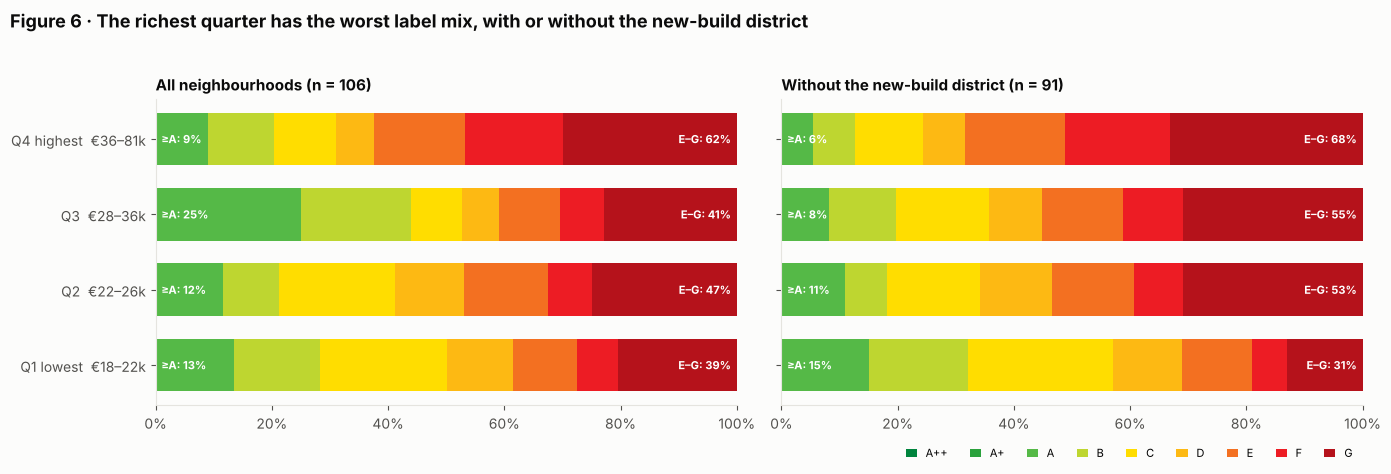

In [11]:
def quartile_mix(frame):
    q = pd.qcut(frame["income"], 4, labels=["Q1\nlowest", "Q2", "Q3", "Q4\nhighest"])
    tot = frame.groupby(q, observed=True)[LABELS].sum()          # pool homes within each quartile
    rng = frame.groupby(q, observed=True)["income"].agg(["min", "max"])
    return tot.div(tot.sum(axis=1), axis=0) * 100, rng

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, (title, frame) in zip(axes, [("All neighbourhoods", an), ("Without the new-build district", an[an["area"] == "Rest of the city"])]):
    mix, rng = quartile_mix(frame)
    left = np.zeros(len(mix))
    for lab, col in zip(LABELS, LABEL_COLORS):
        ax.barh(range(len(mix)), mix[lab], left=left, color=col, height=.7, label=lab)
        left += mix[lab].to_numpy()
    for i, (a, e) in enumerate(zip(mix[["A++", "A+", "A"]].sum(axis=1), mix[["E", "F", "G"]].sum(axis=1))):
        ax.text(1, i, f"≥A: {a:.0f}%", va="center", fontsize=8, color="white", fontweight="bold")
        ax.text(99, i, f"E–G: {e:.0f}%", va="center", ha="right", fontsize=8, color="white", fontweight="bold")
    ax.set_yticks(range(len(mix)), [f"{q}  €{lo/1000:.0f}–{hi/1000:.0f}k".replace("\n", " ") for q, (lo, hi) in zip(mix.index, rng.to_numpy())])
    ax.invert_yaxis(); ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(pct); ax.grid(False)
    ax.set_title(f"{title} (n = {len(frame)})")
axes[1].legend(ncol=9, loc="upper right", bbox_to_anchor=(1, -0.1), fontsize=8, handlelength=1)
figure_title(fig, "The richest quarter has the worst label mix, with or without the new-build district", y=1.03)
fig.tight_layout()
save(fig, "quartile_label_mix")

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>In the full city, the <b>richest quarter has the worst mix</b>: 62% of its labelled homes are E–G, against 39% in the poorest quarter. The third quarter looks best only because most new-build neighbourhoods fall in the €28–36k range. With them removed (right panel), the trend is steady: the E–G share rises from 31% in the poorest quarter to 53%, 55% and 68% as income goes up, while the share of A-or-better falls from 15% to 6%.</div>

**High-income neighbourhoods vs the rest: a direct test of H1.**
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>The hypothesis is about <i>high-income</i> neighbourhoods specifically, so this compares the top quarter with the other three quarters on all three measures. The <b>Mann-Whitney U test</b> asks whether values in one group tend to be larger than in the other, without assuming normal distributions.</div>

In [12]:
rows = []
for col, label in [("pct_A_or_better", "% A-label or better"), ("pct_E_to_G", "% E–G"), ("label_score", "Average label score (1–9)")]:
    hi, lo = an.loc[an["high_income"], col], an.loc[~an["high_income"], col]
    u, p = mannwhitneyu(hi, lo, alternative="two-sided")
    rows.append({"measure": label, "high income (median)": hi.median(), "rest (median)": lo.median(),
                 "direction": "high income better" if (hi.median() > lo.median()) == (col != "pct_E_to_G") else "high income worse",
                 "Mann-Whitney p": fmt_p(p)})
h1_table = pd.DataFrame(rows).set_index("measure")
print(f"High income: n = {an['high_income'].sum()} · rest: n = {(~an['high_income']).sum()}")
h1_table

High income: n = 27 · rest: n = 79


,high income (median),rest (median),direction,Mann-Whitney p
measure,,,,
% A-label or better,3.85,9.68,high income worse,0.022
% E–G,70.54,39.74,high income worse,0.002
Average label score (1–9),3.11,4.01,high income worse,0.013


<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>H1 is <b>rejected</b>. High-income neighbourhoods (above €35,575, n = 27) are worse on every measure: median 3.9% A-or-better vs 9.7% for the rest, 70.5% E–G vs 39.7%, and an average label score of 3.1 (between F and E) vs 4.0 (D). All three differences are significant (p = 0.022, 0.002 and 0.013).</div>

<a id="age"></a>
## 🏗️ 6. The building-age effect

The dataset has no construction year, but the **new-build district** flag is a good stand-in: Leidschenveen-Ypenburg was built almost entirely after 1995, under recent building codes. If housing age drives labels, the income–label link should look very different inside and outside that district.
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>This is the step the original analysis skipped. Its top-5 list was made up of new-build areas, and the conclusion ("no correlation") came from mixing two groups that behave in opposite ways. A <b>forest plot</b> puts every correlation with its 95% bootstrap confidence interval on one axis, so the size, direction and uncertainty of each one can be read at a glance.</div>

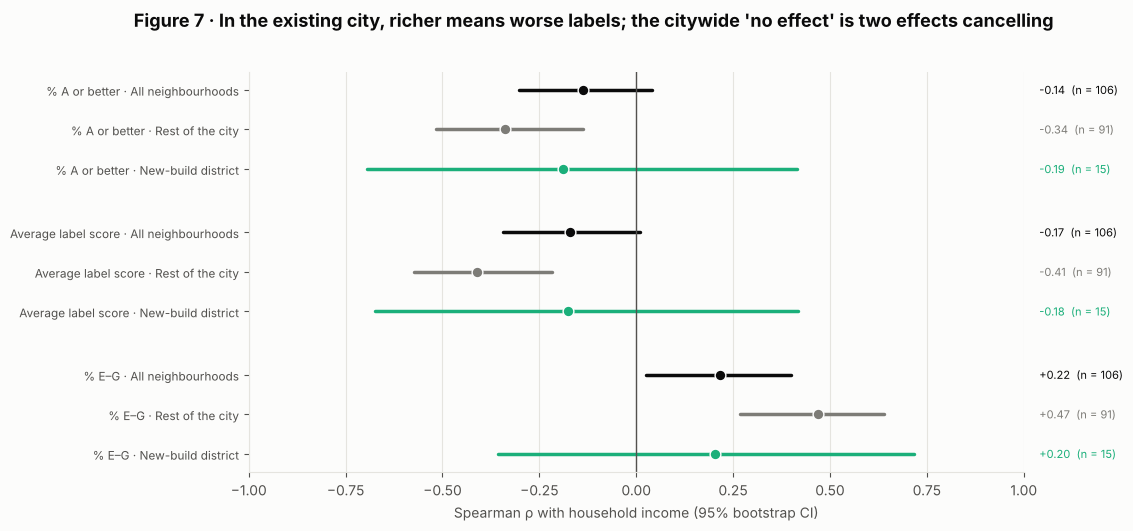

,,n,rho,ci_low,ci_high,p
measure,group,,,,,
% A or better,All neighbourhoods,106,-0.14,-0.30,0.04,0.157
Average label score,All neighbourhoods,106,-0.17,-0.34,0.01,0.081
% E–G,All neighbourhoods,106,0.22,0.02,0.40,0.027
% A or better,Rest of the city,91,-0.34,-0.52,-0.14,0.001
Average label score,Rest of the city,91,-0.41,-0.57,-0.22,< 0.001
% E–G,Rest of the city,91,0.47,0.27,0.64,< 0.001
% A or better,New-build district,15,-0.19,-0.70,0.42,0.498
Average label score,New-build district,15,-0.18,-0.67,0.42,0.528
% E–G,New-build district,15,0.20,-0.36,0.72,0.468


In [13]:
groups = {"All neighbourhoods": an,
          "Rest of the city": an[an["area"] == "Rest of the city"],
          "New-build district": an[an["area"] != "Rest of the city"]}
measures = {"pct_A_or_better": "% A or better", "label_score": "Average label score", "pct_E_to_G": "% E–G"}
res = []
for g, frame in groups.items():
    for col, mlabel in measures.items():
        rho, p, lo, hi = spearman_ci(frame["income"], frame[col])
        res.append({"group": g, "measure": mlabel, "n": len(frame), "rho": rho, "ci_low": lo, "ci_high": hi, "p": fmt_p(p)})
corr = pd.DataFrame(res)

fig, ax = plt.subplots(figsize=(10, 5.2))
colors = {"All neighbourhoods": INK, "Rest of the city": "#7d7c77", "New-build district": AQUA}
ypos, yt = 0, []
for m in measures.values():
    for g in groups:
        r = corr[(corr["group"] == g) & (corr["measure"] == m)].iloc[0]
        ax.plot([r["ci_low"], r["ci_high"]], [ypos, ypos], color=colors[g], lw=2.5, solid_capstyle="round")
        ax.scatter(r["rho"], ypos, color=colors[g], s=60, zorder=3, edgecolor="white")
        ax.text(1.04, ypos, f"{r['rho']:+.2f}  (n = {r['n']})", va="center", fontsize=8, color=colors[g])
        yt.append((ypos, f"{m} · {g}"))
        ypos -= 1
    ypos -= 0.6
ax.axvline(0, color=MUTED, lw=1)
ax.set_yticks([y for y, _ in yt], [t for _, t in yt], fontsize=8.5)
ax.set_xlim(-1, 1.0); ax.set_xlabel("Spearman ρ with household income (95% bootstrap CI)")
ax.grid(axis="y", visible=False)
figure_title(fig, "In the existing city, richer means worse labels; the citywide 'no effect' is two effects cancelling", y=1.0)
save(fig, "forest_correlations")
corr.round(2).set_index(["measure", "group"])

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>Outside the new-build district, all three correlations point the same way and none of their confidence intervals cross zero: higher income goes with fewer A-labels (ρ = −0.34), a lower average label (ρ = −0.41) and more E–G homes (ρ = +0.47). Inside the new-build district (n = 15), the intervals are wide and include zero: everyone there lives in recent housing, so income makes no clear difference. Combining the two groups gives the weak citywide result. Building age, not income, is what separates good labels from bad ones.</div>

<div style="background:#fdf0ea;border-left:5px solid #eb6834;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">⚠️ <b>Caution</b><br>The new-build flag is only a rough stand-in for building age. Other recently built or renovated areas (Hoge Veld, Kraayenstein, Laakhaven, Binckhorst) are counted in the 'rest of the city' group, which if anything <i>weakens</i> the negative link found there. A proper test would use the average construction year per neighbourhood, which Den Haag in Cijfers also publishes. Part of the label pattern may also reflect who registered labels: most older homes received a <i>provisional</i> label in 2015 based mainly on building type and year, while housing associations registered full labels after renovating their stock, which is concentrated in lower-income areas.</div>

<a id="moran"></a>
## 🧲 7. Spatial clustering: do similar neighbourhoods sit together?

**Moran's I** measures whether neighbouring areas have similar values. It is about 0 when values are scattered randomly across the map, and positive when high values sit next to high values and low next to low. Two neighbourhoods count as neighbours when their boundaries touch (*queen contiguity*).
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>The maps suggest clear clusters: wealthy dune-side areas in the north-west and A-label new builds in the south-east. Moran's I tests this formally. It also matters for the correlations above: neighbouring areas are not fully independent observations, so p-values from ordinary tests are somewhat too optimistic when there is strong clustering. To get a p-value, the values are shuffled randomly over the map 999 times and the real I is compared with those shuffled ones.</div>

Neighbours per area: mean 4.9, min 1, max 12 · areas with none: 0


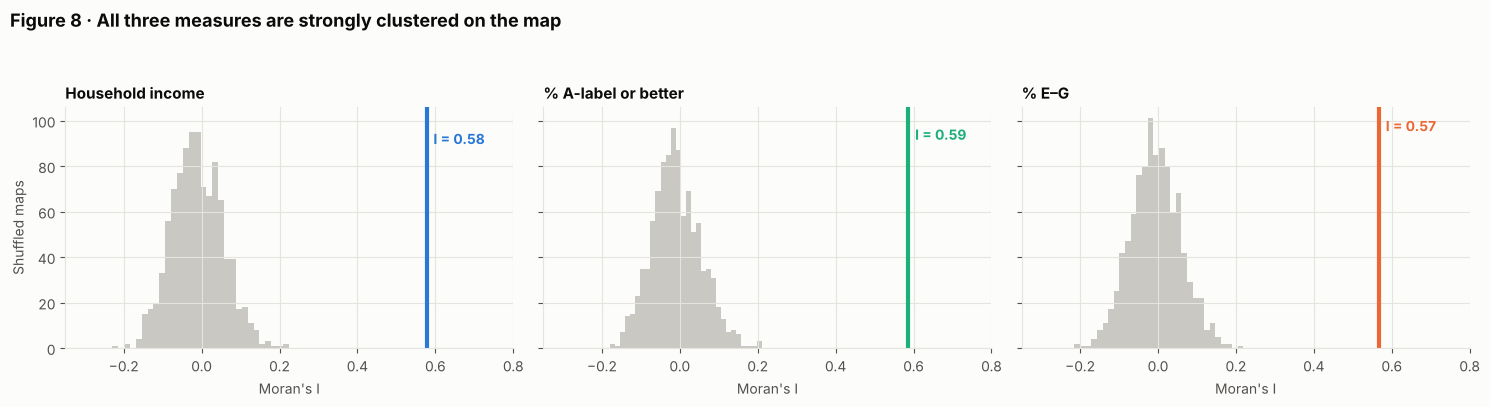

,Moran's I,p (999 permutations),expected if random
Household income,0.58,0.001,-0.01
% A-label or better,0.59,0.001,-0.01
% E–G,0.57,0.001,-0.01


In [14]:
geo_an = geo_raw.merge(an, left_on="neighbourhood", right_index=True, how="inner").reset_index(drop=True)
W = queen_weights(geo_an)
n_nb = (W > 0).sum(axis=1)
print(f"Neighbours per area: mean {n_nb.mean():.1f}, min {n_nb.min()}, max {n_nb.max()} · areas with none: {(n_nb == 0).sum()}")

moran = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
for ax, (col, label, color) in zip(axes, [("income", "Household income", BLUE),
                                          ("pct_A_or_better", "% A-label or better", AQUA),
                                          ("pct_E_to_G", "% E–G", ORANGE)]):
    I, p, sims = morans_i(geo_an[col], W)
    moran[label] = {"Moran's I": I, "p (999 permutations)": fmt_p(p), "expected if random": -1 / (len(W) - 1)}
    ax.hist(sims, bins=30, color="#c9c8c2")
    ax.axvline(I, color=color, lw=3)
    ax.text(I, ax.get_ylim()[1] * .9, f"  I = {I:.2f}", color=color, fontweight="bold", fontsize=10)
    ax.set_title(label); ax.set_xlabel("Moran's I")
    ax.set_xlim(-0.35, max(0.8, I + 0.1))
axes[0].set_ylabel("Shuffled maps")
figure_title(fig, "All three measures are strongly clustered on the map", y=1.06)
fig.tight_layout()
save(fig, "morans_i")
pd.DataFrame(moran).T

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>All three measures are strongly clustered: Moran's I is 0.58 for income, 0.59 for the A-label share and 0.57 for the E–G share. None of the 999 random shuffles came close (p = 0.001, the smallest possible with 999 shuffles). Neighbourhoods look like their neighbours, so the 106 areas are not fully independent observations. The p-values in sections 5 and 6 are therefore somewhat optimistic, although the main contrast (ρ = +0.47 for E–G outside the new-build district) is large enough that the conclusion is unlikely to change.</div>

<a id="five"></a>
## 🏅 8. Five neighbourhoods

The assignment asks for **five neighbourhoods** that speak to the research question. Two lists are given:

* **The five with the highest share of A-label homes**, as in the original notebook.
* **Five retrofit candidates**: high-income neighbourhoods (top quarter) with the most E–G homes. These are where the hypothesis fails most clearly, and where households are most able to pay for insulation themselves.
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>The first list on its own would suggest that 'good labels' means 'average income', which is really a building-age story. The second list shows the other side: wealth that has not turned into energy efficiency. Together they answer the question better than either one alone.</div>

In [15]:
top_A = an.nlargest(5, "pct_A_or_better")
retrofit = an[an["high_income"]].nlargest(5, "pct_E_to_G")
cols = ["income", "labelled_homes", "pct_A_or_better", "pct_E_to_G", "label_score", "area"]
print("🟢 Highest share of A-label homes")
display(top_A[cols])
print("🔴 High income, most E–G homes (retrofit candidates)")
display(retrofit[cols])

🟢 Highest share of A-label homes


,income,labelled_homes,pct_A_or_better,pct_E_to_G,label_score,area
neighbourhood,,,,,,
111 De Venen,"28,900.00",738.00,95.66,0.00,6.95,New-build (Leidschenveen-Ypenburg)
121 Rietbuurt,"34,200.00",902.00,95.01,2.11,6.84,New-build (Leidschenveen-Ypenburg)
102 Hoge Veld,"31,500.00","3,106.00",89.38,1.13,6.83,New-build (Leidschenveen-Ypenburg)
118 De Lanen,"34,200.00","1,780.00",82.53,0.96,6.77,New-build (Leidschenveen-Ypenburg)
60 Binckhorst,"17,500.00",595.00,76.13,2.69,6.39,Rest of the city


🔴 High income, most E–G homes (retrofit candidates)


,income,labelled_homes,pct_A_or_better,pct_E_to_G,label_score,area
neighbourhood,,,,,,
68 Marlot,"64,700.00",357.00,0.28,94.40,1.85,Rest of the city
74 Duttendel,"80,900.00",617.00,0.97,91.90,2.69,Rest of the city
48 Nassaubuurt,"65,700.00",749.00,1.87,88.65,1.98,Rest of the city
79 v Hoytemastraat eo,"46,400.00","1,045.00",0.67,87.46,1.81,Rest of the city
09 Vogelwijk,"52,400.00","2,125.00",5.84,86.21,2.23,Rest of the city


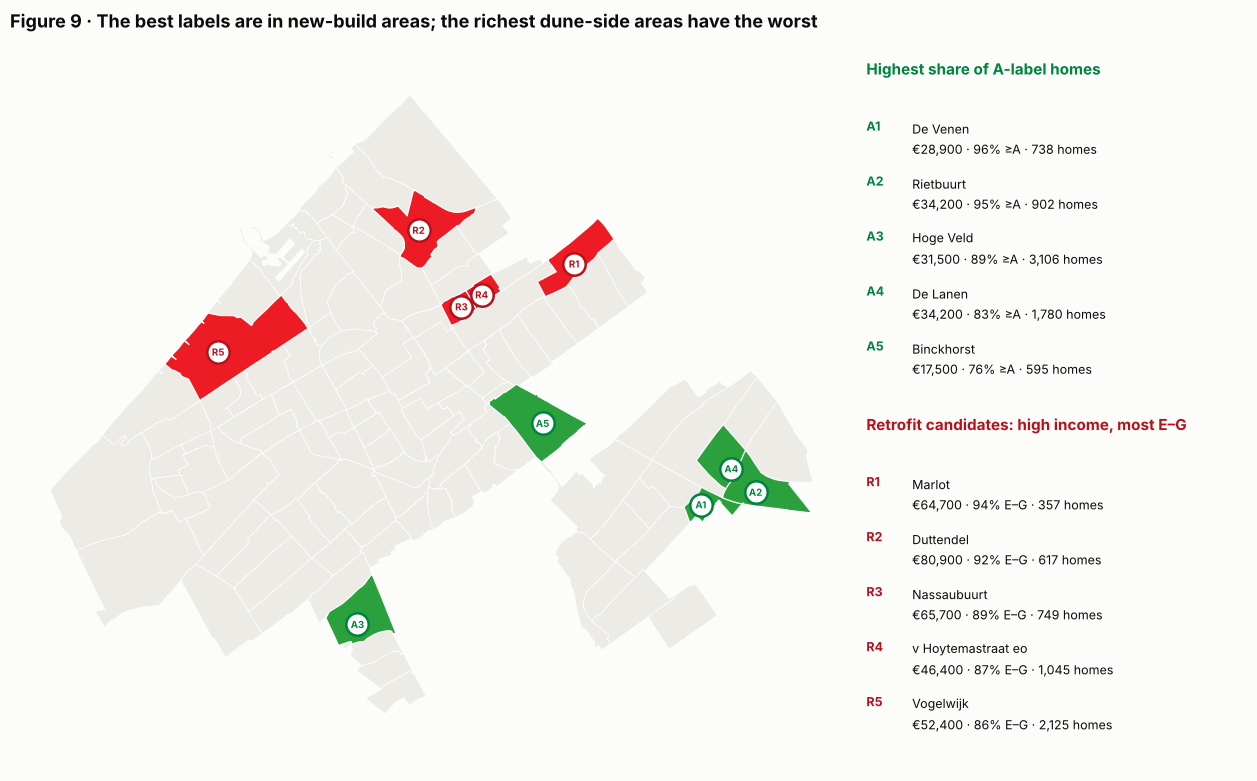

In [16]:
fig, (ax, tx) = plt.subplots(1, 2, figsize=(13, 8), width_ratios=[2.2, 1])
nb.plot(ax=ax, color="#ecebe6", edgecolor="white", linewidth=0.5)
groups5 = [("A", top_A, LABEL_COLORS[1], LABEL_COLORS[0], "🟢 Highest share of A-label homes", "pct_A_or_better", "≥A"),
           ("R", retrofit, LABEL_COLORS[7], LABEL_COLORS[8], "🔴 Retrofit candidates: high income, most E–G", "pct_E_to_G", "E–G")]
tx.set_axis_off(); ty = 0.95
for tag, frame, fill, dark, head, col, unit in groups5:
    sel = nb[nb["neighbourhood"].isin(frame.index)]
    sel.plot(ax=ax, color=fill, edgecolor="white", linewidth=0.8)
    pts = sel.geometry.representative_point()
    pos = dict(zip(sel["neighbourhood"], zip(pts.x, pts.y)))
    tx.text(0, ty, head.split(" ", 1)[1], fontsize=11, fontweight="bold", color=dark, transform=tx.transAxes); ty -= 0.06
    for k, (name, r) in enumerate(frame.iterrows(), 1):
        x, y = pos[name]
        ax.scatter(x, y, s=260, color="white", edgecolor=dark, linewidth=1.8, zorder=4)
        ax.text(x, y, f"{tag}{k}", ha="center", va="center", fontsize=7, fontweight="bold", color=dark, zorder=5)
        tx.text(0, ty, f"{tag}{k}", fontsize=9, fontweight="bold", color=dark, va="top", transform=tx.transAxes)
        tx.text(0.12, ty, f"{name.split(' ', 1)[1]}\n€{r['income']:,.0f} · {r[col]:.0f}% {unit} · {r['labelled_homes']:,.0f} homes",
                fontsize=9, color=INK, va="top", transform=tx.transAxes, linespacing=1.4)
        ty -= 0.075
    ty -= 0.05
map_axis(ax)
figure_title(fig, "The best labels are in new-build areas; the richest dune-side areas have the worst", y=0.97)
fig.tight_layout()
save(fig, "five_neighbourhoods")

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>**Highest share of A-label homes** (same five as in the original notebook): De Venen (96%), Rietbuurt (95%), Hoge Veld (89%), De Lanen (83%) and Binckhorst (76%). Four are in Leidschenveen-Ypenburg, all with incomes of €28,900–34,200, close to the city median. The fifth, Binckhorst, is a former industrial area with new apartments and has the <b>lowest income in the city</b> (€17,500).

**Retrofit candidates**: Marlot (94% E–G), Duttendel (92%), Nassaubuurt (89%), Van Hoytemastraat (87%) and Vogelwijk (86%). All have incomes of €46,400–80,900, in the top quarter of the city, and are pre-war villa or garden-suburb areas. They combine the worst labels with the most money to fix them.</div>

<div style="background:linear-gradient(135deg,#0f172a 0%,#14532d 100%);padding:18px 24px;border-radius:12px;color:#ffffff;font-family:Helvetica,Arial,sans-serif;margin-top:20px">
  <div style="font-size:12px;letter-spacing:2px;text-transform:uppercase;opacity:.8">Part II · Unsupervised learning</div>
  <div style="font-size:24px;font-weight:700;margin-top:6px">🧩 Neighbourhood types by energy-label mix (K-means)</div>
</div>

Part I compared neighbourhoods one measure at a time. Part II lets the data group them: **K-means clustering** sorts the neighbourhoods into a small number of *types* that have similar label mixes. The questions are:

1. What kinds of neighbourhoods does The Hague have, in terms of their label mix?
2. Where are they on the map?
3. Are the types any good: well separated, stable, and spatially coherent?
4. Do the types differ in household income? This links back to the hypothesis from Part I.

<a id="kchoice"></a>
## 🧩 9. Features and the number of clusters

**Features.** The share of labelled homes in each of seven classes: **A-or-better** (A++, A+ and A combined), B, C, D, E, F and G. Every feature is a percentage on the same 0–100 scale, so no further scaling is needed, and the cluster centres can be read directly as "the typical label mix of this type".

**Which neighbourhoods.** All 107 with at least 100 labelled homes. Income is *not* used to build the clusters, so neighbourhoods without an income figure can stay in. Income is only brought back in section 12 to describe the types.
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>K-means needs the number of clusters <i>k</i> in advance. Three checks are combined instead of relying only on the elbow plot: <b>inertia</b> (within-cluster spread, which always falls as k grows; look for the bend), the <b>silhouette score</b> (how much closer each neighbourhood is to its own cluster than to the next one; higher is better), and <b>stability</b> (do different random starts give the same clusters? measured with the adjusted Rand index, where 1 means identical). A good k is one where the elbow bends, the silhouette is high and the result does not depend on the random seed.</div>

107 neighbourhoods × 7 features


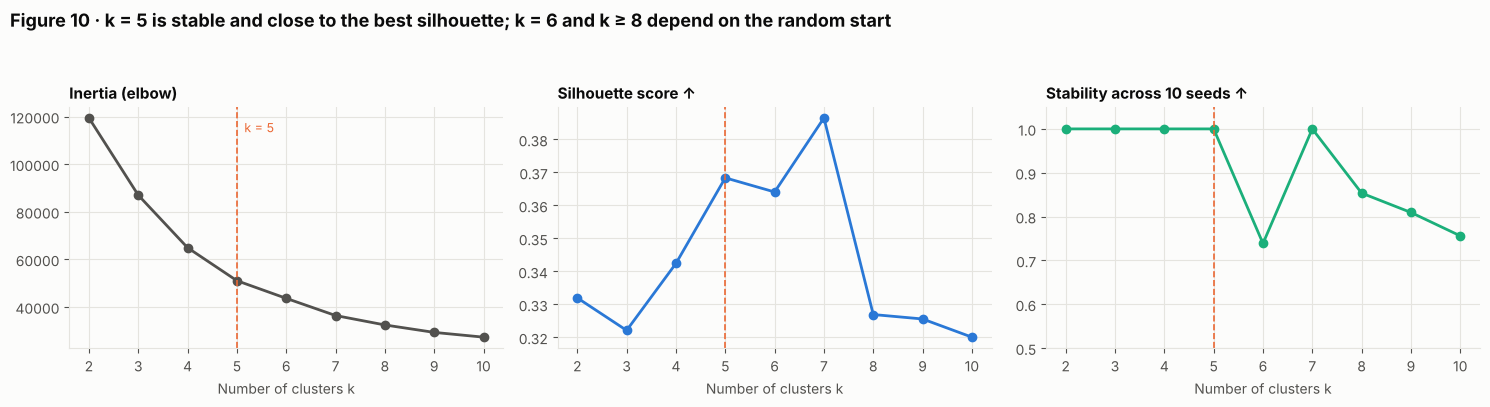

,inertia,silhouette,stability (min ARI),smallest cluster
k,,,,
2,"119,441.22",0.33,1.00,36
3,"86,992.18",0.32,1.00,27
4,"64,894.11",0.34,1.00,17
5,"51,031.48",0.37,1.00,6
6,"43,611.98",0.36,0.74,6
7,"36,392.98",0.39,1.00,6
8,"32,431.08",0.33,0.85,6
9,"29,300.59",0.33,0.81,6
10,"27,303.21",0.32,0.76,5


In [17]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
from scipy.stats import kruskal

FEATURES = ["≥A", "B", "C", "D", "E", "F", "G"]
FEATURE_COLORS = [LABEL_COLORS[2]] + LABEL_COLORS[3:]

cl = df[df["labelled_homes"] >= MIN_HOMES].copy()
X = cl[LABELS].div(cl["labelled_homes"], axis=0) * 100
X["≥A"] = X[["A++", "A+", "A"]].sum(axis=1)
X = X[FEATURES]
print(f"{len(X)} neighbourhoods × {X.shape[1]} features")

K_RANGE = range(2, 11)
scan = []
for k in K_RANGE:
    base = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    ari = [adjusted_rand_score(base.labels_, KMeans(n_clusters=k, n_init=50, random_state=s).fit(X).labels_)
           for s in range(1, 11)]
    scan.append({"k": k, "inertia": base.inertia_, "silhouette": silhouette_score(X, base.labels_),
                 "stability (min ARI)": min(ari), "smallest cluster": np.bincount(base.labels_).min()})
scan = pd.DataFrame(scan).set_index("k")

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, color, title in [(axes[0], "inertia", MUTED, "Inertia (elbow)"),
                              (axes[1], "silhouette", BLUE, "Silhouette score ↑"),
                              (axes[2], "stability (min ARI)", AQUA, "Stability across 10 seeds ↑")]:
    ax.plot(scan.index, scan[col], marker="o", color=color)
    ax.axvline(5, color=ORANGE, ls="--", lw=1.2)
    ax.set_title(title); ax.set_xlabel("Number of clusters k"); ax.set_xticks(list(K_RANGE))
axes[0].text(5.15, scan["inertia"].max() * .95, "k = 5", color=ORANGE, fontsize=9)
axes[2].set_ylim(0.5, 1.05)
figure_title(fig, "k = 5 is stable and close to the best silhouette; k = 6 and k ≥ 8 depend on the random start", y=1.06)
fig.tight_layout()
save(fig, "choose_k")
scan.round(3)

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>The elbow plot has no sharp bend: inertia falls steadily, which is why the original notebook leaned towards 9 clusters. The other two checks are clearer. At <b>k = 5</b> the silhouette is 0.37, close to the best value, and all 10 random starts give exactly the same clusters (ARI = 1.00). k = 7 scores slightly higher (0.39), but it gets there by splitting the mixed and E-heavy groups into sub-types that differ by only a few percentage points. At k = 6 and at k = 8–10 the result changes with the random start (ARI 0.74–0.85), so those extra clusters are not robust. k = 5, the number the original notebook started with, is kept.</div>

<a id="types"></a>
## 🗂️ 10. The five neighbourhood types
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>Cluster numbers from K-means are arbitrary (cluster 0 is not 'better' than cluster 3). To make the result readable, the clusters are <b>ordered by their average label score</b> and <b>named after their label mix</b>, and each type gets the label colour that matches its typical label. The names describe the label mix only, not the age or type of the housing.</div>

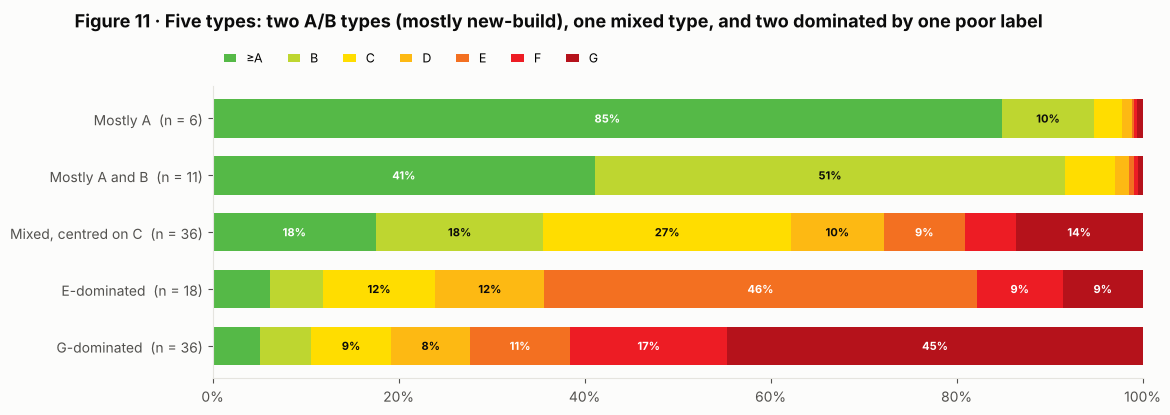

,≥A,B,C,D,E,F,G
Mostly A,84.90,9.90,3.00,1.10,0.30,0.30,0.60
Mostly A and B,41.10,50.50,5.40,1.40,0.50,0.50,0.50
"Mixed, centred on C",17.60,18.00,26.60,9.90,8.80,5.40,13.60
E-dominated,6.20,5.60,12.10,11.70,46.50,9.30,8.60
G-dominated,5.10,5.50,8.70,8.50,10.70,16.90,44.60


In [18]:
K = 5
km = KMeans(n_clusters=K, n_init=50, random_state=42).fit(X)
cl["cluster_raw"] = km.labels_

# order clusters from best to worst average label and give them readable names
score_by_cluster = cl.groupby("cluster_raw")["label_score"].mean().sort_values(ascending=False)
centres = pd.DataFrame(km.cluster_centers_, columns=FEATURES).loc[score_by_cluster.index]

def name_type(c):
    if c["≥A"] >= 60:  return "Mostly A"
    if c["≥A"] + c["B"] >= 60: return "Mostly A and B"
    if c["G"] >= 35:  return "G-dominated"
    if c["E"] >= 35:  return "E-dominated"
    return "Mixed, centred on C"

TYPE_NAMES = [name_type(centres.loc[i]) for i in score_by_cluster.index]
assert len(set(TYPE_NAMES)) == K, TYPE_NAMES        # every cluster gets its own name
cl["type"] = pd.Categorical(cl["cluster_raw"].map(dict(zip(score_by_cluster.index, TYPE_NAMES))),
                            categories=TYPE_NAMES, ordered=True)
centres.index = TYPE_NAMES
TYPE_COLORS = dict(zip(TYPE_NAMES, [LABEL_COLORS[0], LABEL_COLORS[3], LABEL_COLORS[4], LABEL_COLORS[6], LABEL_COLORS[8]]))

# 📊 profile chart: the cluster centre = the typical label mix of each type
sizes = cl["type"].value_counts().reindex(TYPE_NAMES)
fig, ax = plt.subplots(figsize=(12, 3.8))
left = np.zeros(K)
for f, col in zip(FEATURES, FEATURE_COLORS):
    ax.barh(range(K), centres[f], left=left, color=col, height=.68, label=f)
    for i, (l, v) in enumerate(zip(left, centres[f])):
        if v >= 7:
            ax.text(l + v / 2, i, f"{v:.0f}%", ha="center", va="center", fontsize=8,
                    color="white" if f in ["≥A", "E", "F", "G"] else INK, fontweight="bold")
    left += centres[f].to_numpy()
ax.set_yticks(range(K), [f"{t}  (n = {n})" for t, n in zip(TYPE_NAMES, sizes)])
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.xaxis.set_major_formatter(pct); ax.grid(False)
ax.legend(ncol=7, loc="upper left", bbox_to_anchor=(0, 1.16), fontsize=9, handlelength=1)
figure_title(fig, "Five types: two A/B types (mostly new-build), one mixed type, and two dominated by one poor label", y=1.08)
save(fig, "cluster_profiles")
centres.round(1)

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>The five types, from best to worst average label:

* **Mostly A** (6 neighbourhoods): 85% A-or-better. Recent developments: four in Leidschenveen-Ypenburg, plus Hoge Veld and Binckhorst.
* **Mostly A and B** (11): about 40% A and 50% B. The rest of the new-build district, plus Kraayenstein & Vroondaal.
* **Mixed, centred on C** (36): no single label above 27%, with something in every class. The renewed inner-city and southern areas fall here.
* **E-dominated** (18): almost half the homes are E.
* **G-dominated** (36): 45% G and 17% F, with less than 11% of homes at B or better.

The two poorest types cover 54 of the 107 neighbourhoods. The original notebook dropped A++ and A+ as near-empty; here they are merged into ≥A, so no homes are lost.</div>

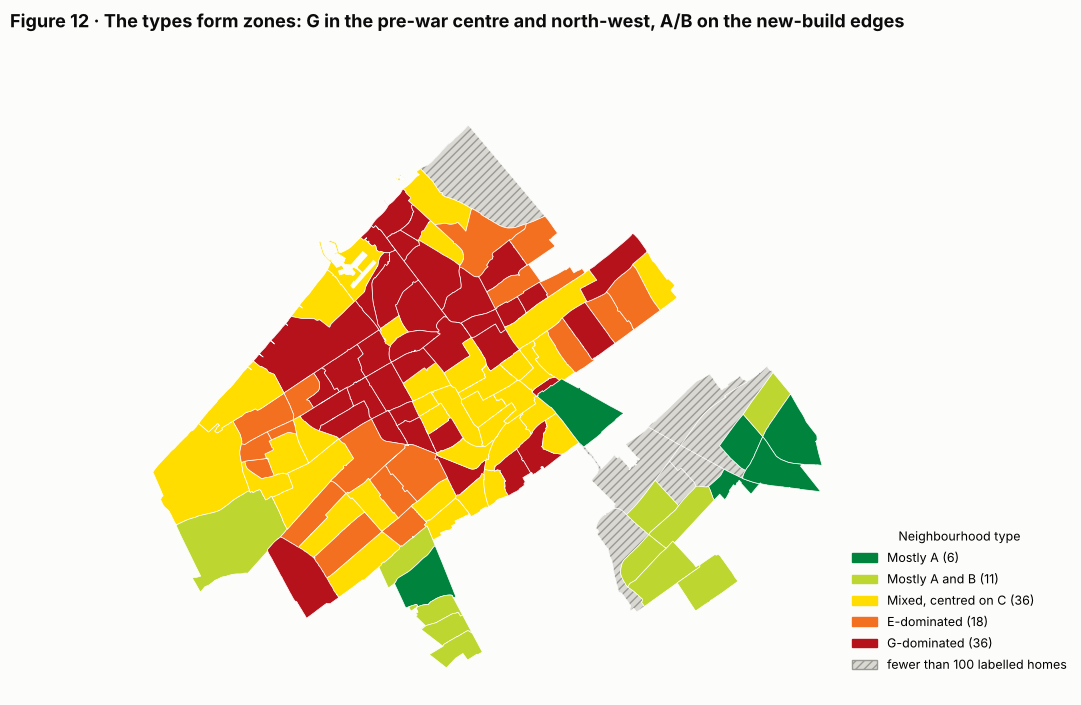

In [19]:
geo_cl = nb.merge(cl[["type"]], left_on="neighbourhood", right_index=True, how="left")
fig, ax = plt.subplots(figsize=(9.5, 8.5))
geo_cl[geo_cl["type"].isna()].plot(ax=ax, color=NODATA, edgecolor="white", linewidth=0.4, hatch="////")
known = geo_cl[geo_cl["type"].notna()]
known.plot(ax=ax, color=[TYPE_COLORS[t] for t in known["type"]], edgecolor="white", linewidth=0.5)
map_axis(ax)
ax.legend(handles=[Patch(color=TYPE_COLORS[t], label=f"{t} ({sizes[t]})") for t in TYPE_NAMES]
                  + [Patch(facecolor=NODATA, hatch="////", edgecolor="#9a9993", label="fewer than 100 labelled homes")],
          loc="lower left", bbox_to_anchor=(0.98, 0.02), fontsize=9, title="Neighbourhood type", title_fontsize=9)
figure_title(fig, "The types form zones: G in the pre-war centre and north-west, A/B on the new-build edges", y=0.95)
save(fig, "cluster_map")

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>Although K-means never saw the map, the types come out as clear zones. <b>G-dominated</b> neighbourhoods form one large block across the pre-war centre and the north-west (Statenkwartier, Archipelbuurt, Zeeheldenkwartier, the Bomen-/Bloemenbuurt, Benoordenhout) and reach down into Laakkwartier and Transvaal-Zuid. <b>Mixed</b> areas form a belt through the inner south (Schilderswijk, Transvaal, Moerwijk), where much housing was rebuilt during urban renewal. <b>E-dominated</b> neighbourhoods appear in patches, mostly in the post-war south-west (Bohemen, Leyenburg, Morgenstond) and the north-east (Duttendel, Uilennest, Kampen, Burgen en Horsten). The A and A/B types sit on the edges: the new-build east and the south-west tip.</div>

<a id="evaluate"></a>
## 🧪 11. How good are the clusters?

Clustering has no "right answer" to score against, so the evaluation uses three angles:

| Check | Question |
|---|---|
| **Silhouette per neighbourhood** | Which neighbourhoods fit their type well, and which sit on the border between two types? |
| **Dominant label** | Do the types agree with the simple rule "colour each neighbourhood by its most common label", which the original notebook used? |
| **Spatial coherence** | Are neighbouring areas more often of the same type than chance would give? K-means never saw the map, so a yes here is independent evidence that the types are real. |
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>A single average silhouette can hide a few badly placed neighbourhoods. Looking at each one shows <i>where</i> the model is unsure, which is the clustering version of an error analysis.</div>

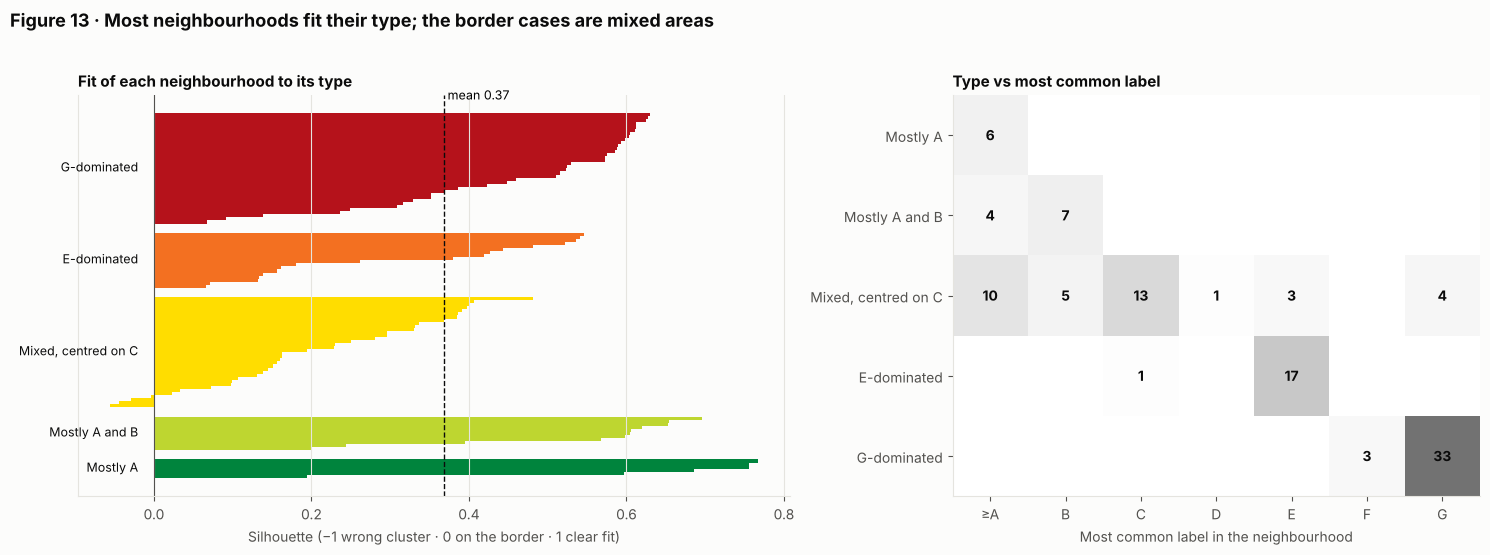

Five weakest fits (lowest silhouette):


,type,dominant_label,silhouette,≥A,B,C,D,E,F,G
neighbourhood,,,,,,,,,,
71 Belgisch Park,"Mixed, centred on C",C,-0.06,2.00,8.00,33.00,6.00,8.00,13.00,31.00
26 Noordpolderbuurt,"Mixed, centred on C",G,-0.04,4.00,14.00,31.00,8.00,3.00,3.00,36.00
10 Rond de Energiecentrale,"Mixed, centred on C",G,-0.03,23.00,9.00,17.00,6.00,5.00,10.00,30.00
87 Venen/Oorden/Raden,"Mixed, centred on C",E,-0.00,9.00,3.00,22.00,15.00,23.00,14.00,15.00
90 Ockenburgh,"Mixed, centred on C",B,0.02,3.00,52.00,26.00,16.00,0.00,1.00,2.00


In [20]:
cl["silhouette"] = silhouette_samples(X, km.labels_)
cl["dominant_label"] = pd.Categorical(X.idxmax(axis=1), categories=FEATURES, ordered=True)

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(15, 5.4), width_ratios=[1.35, 1])
y0 = 0
for t in TYPE_NAMES:
    s = cl.loc[cl["type"] == t, "silhouette"].sort_values()
    ax.barh(np.arange(y0, y0 + len(s)), s, color=TYPE_COLORS[t], height=1.0)
    ax.text(-0.02, y0 + len(s) / 2, t, ha="right", va="center", fontsize=9, color=INK)
    y0 += len(s) + 3
avg = cl["silhouette"].mean()
ax.axvline(avg, color=INK, ls="--", lw=1); ax.text(avg, y0, f" mean {avg:.2f}", fontsize=9, va="bottom")
ax.axvline(0, color=MUTED, lw=.8)
ax.set_yticks([]); ax.grid(axis="y", visible=False); ax.set_xlabel("Silhouette (−1 wrong cluster · 0 on the border · 1 clear fit)")
ax.set_title("Fit of each neighbourhood to its type")

ct = pd.crosstab(cl["type"], cl["dominant_label"]).reindex(columns=FEATURES, fill_value=0)
ax2.imshow(ct.to_numpy(), cmap="Greys", aspect="auto", vmin=0, vmax=ct.to_numpy().max() * 1.6)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        v = ct.iat[i, j]
        if v:
            ax2.text(j, i, v, ha="center", va="center", fontsize=10, fontweight="bold", color=INK)
ax2.set_xticks(range(len(FEATURES)), FEATURES); ax2.set_yticks(range(K), TYPE_NAMES)
ax2.set_xlabel("Most common label in the neighbourhood"); ax2.grid(False)
ax2.set_title("Type vs most common label")
figure_title(fig, "Most neighbourhoods fit their type; the border cases are mixed areas", y=1.02)
fig.tight_layout()
save(fig, "cluster_evaluation")
print("Five weakest fits (lowest silhouette):")
cl.nsmallest(5, "silhouette")[["type", "dominant_label", "silhouette"]].join(X.round(0))

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>The average silhouette is 0.37, and 103 of the 107 neighbourhoods are positive, so they are closer to their own type than to any other. The four weakest fits are all in the <b>mixed</b> type. Belgisch Park, Noordpolderbuurt and Rond de Energiecentrale have slightly negative scores because they combine a lot of C <i>and</i> 30–36% G, which puts them between the mixed and G-dominated types. These are the model's 'errors'. The right panel compares the types with the original rule of colouring by the most common label. The two agree for the clear-cut types: 33 of the 36 G-dominated neighbourhoods have G as their most common label (the other 3 have F), and 17 of the 18 E-dominated have E. The mixed type is what K-means adds: 36 neighbourhoods whose most common label ranges from A to G, which the most-common-label rule would have scattered across six different colours.</div>

In [21]:
# 🧲 spatial coherence: share of neighbouring pairs that are the same type, vs random shuffles of the types
geo_k = geo_raw.merge(cl[["type"]], left_on="neighbourhood", right_index=True, how="inner").reset_index(drop=True)
A = (queen_weights(geo_k) > 0).astype(int)
types = geo_k["type"].astype(str).to_numpy()
pairs = np.argwhere(np.triu(A))

def same_share(t):
    return (t[pairs[:, 0]] == t[pairs[:, 1]]).mean()

observed = same_share(types)
rng = np.random.default_rng(42)
shuffled = np.array([same_share(rng.permutation(types)) for _ in range(999)])
p_same = (1 + (shuffled >= observed).sum()) / 1000
print(f"Neighbouring pairs: {len(pairs)}")
print(f"Same type: {observed:.0%} of pairs  ·  random shuffles: {shuffled.mean():.0%} on average "
      f"(max {shuffled.max():.0%})  ·  p = {fmt_p(p_same)}")

Neighbouring pairs: 266
Same type: 50% of pairs  ·  random shuffles: 26% on average (max 37%)  ·  p = 0.001


<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>Half (50%) of all neighbouring pairs are of the same type. When the types are shuffled randomly over the map, the average is 26% and the highest of 999 shuffles is 37% (p = 0.001). The clustering used only label shares, so this spatial pattern is independent evidence that the types reflect real differences in the housing stock of different parts of the city.</div>

<a id="typeincome"></a>
## 💶 12. Do the types differ in income?
<div style="background:#f3f0ff;border-left:5px solid #6250d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">💡 <b>Why this step</b><br>This links Part II back to the hypothesis. If richer neighbourhoods had better labels, the A and A/B types would have the highest incomes and the G type the lowest. The <b>Kruskal-Wallis test</b> checks whether income differs across the five types at all, without assuming normal distributions. Each dot is a neighbourhood, so the spread inside each type stays visible.</div>

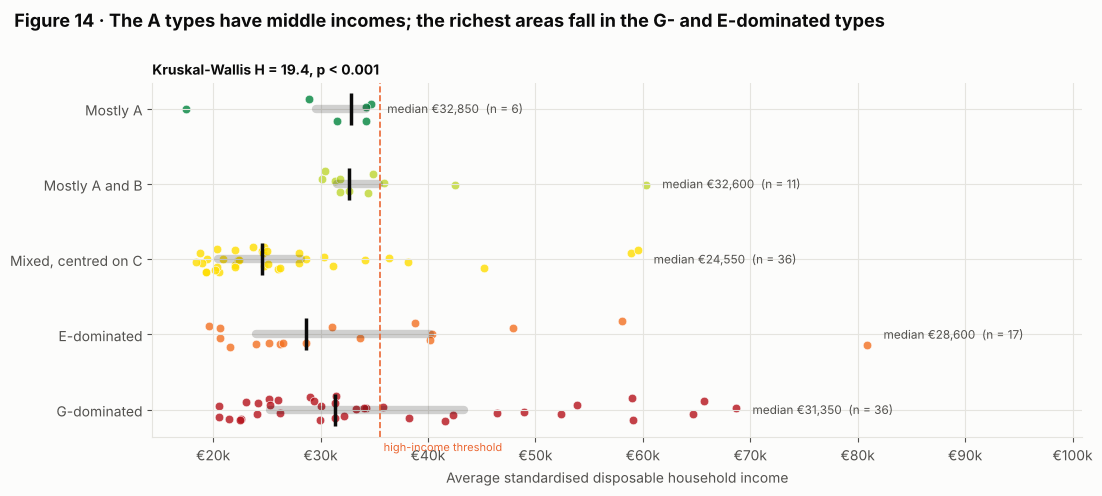

,neighbourhoods,median_income,high_income,new_build
type,,,,
Mostly A,6,"32,850.00",0,5
Mostly A and B,11,"32,600.00",3,10
"Mixed, centred on C",36,"24,550.00",5,0
E-dominated,17,"28,600.00",6,0
G-dominated,36,"31,350.00",13,0


In [22]:
inc = cl.dropna(subset=["income"])
groups_inc = [inc.loc[inc["type"] == t, "income"] for t in TYPE_NAMES]
H, p_kw = kruskal(*groups_inc)

fig, ax = plt.subplots(figsize=(12, 4.6))
rng = np.random.default_rng(1)
for i, (t, g) in enumerate(zip(TYPE_NAMES, groups_inc)):
    ax.scatter(g, i + rng.uniform(-.18, .18, len(g)), s=38, color=TYPE_COLORS[t], alpha=.8, edgecolor="white", linewidth=.5)
    q1, med, q3 = g.quantile([.25, .5, .75])
    ax.plot([q1, q3], [i, i], color=INK, lw=6, alpha=.18, solid_capstyle="round")
    ax.scatter(med, i, marker="|", s=500, color=INK, linewidth=2.5, zorder=3)
    ax.text(g.max() + 1500, i, f"median €{med:,.0f}  (n = {len(g)})", va="center", fontsize=8.5, color=MUTED)
ax.axvline(HIGH_INCOME, color=ORANGE, ls="--", lw=1.2)
ax.text(HIGH_INCOME, K - 0.45, " high-income threshold", color=ORANGE, fontsize=8)
ax.set_yticks(range(K), TYPE_NAMES); ax.invert_yaxis()
ax.xaxis.set_major_formatter(eur); ax.set_xlabel("Average standardised disposable household income")
ax.set_xlim(None, inc["income"].max() + 20000)
ax.set_title(f"Kruskal-Wallis H = {H:.1f}, p {fmt_p(p_kw) if p_kw < 0.001 else '= ' + fmt_p(p_kw)}", fontsize=10)
figure_title(fig, "The A types have middle incomes; the richest areas fall in the G- and E-dominated types", y=1.04)
save(fig, "income_by_type")

summary_types = (inc.groupby("type", observed=True)
                    .agg(neighbourhoods=("income", "size"), median_income=("income", "median"),
                         high_income=("high_income", "sum"), new_build=("area", lambda s: (s != "Rest of the city").sum())))
summary_types

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Insight</b><br>Income does differ between the types (Kruskal-Wallis H = 19.4, p &lt; 0.001), but not in the direction the hypothesis expects. The two A types have <b>middle</b> incomes (medians €32,850 and €32,600). The <b>lowest</b> median is in the mixed type (€24,550), which holds the renewed areas of Schilderswijk, Transvaal and Moerwijk. The <b>G-dominated</b> type holds 13 of the 27 high-income neighbourhoods. It also has the widest income range (€20,500–68,700), because pre-war housing is home both to wealthy villa areas and to low-income areas such as Laakkwartier. The richest neighbourhood of all, Duttendel (€80,900), is E-dominated. This confirms Part I: labels follow the housing stock, and income does not predict which type a neighbourhood belongs to.</div>

<a id="findings"></a>
## 🏁 13. Findings and limitations

<div style="background:#eaf3fd;border-left:5px solid #2a78d6;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">🔎 <b>Answer to the research question</b><br>
High-income neighbourhoods in The Hague do <b>not</b> have more energy-efficient homes. Across the city there is no clear link (ρ = −0.14 for the share of A-label homes). Outside the post-1995 new-build district, richer neighbourhoods have clearly <b>worse</b> labels (ρ = +0.47 with the E–G share). The high-income quarter has a median of 71% E–G homes, against 40% for the rest.</div>

**What drives labels instead.** The best labels are where the housing is newest: Leidschenveen-Ypenburg, plus new or redeveloped areas like Hoge Veld and Binckhorst. The worst labels are in the pre-war villa and townhouse areas near the dunes, which are also where incomes are highest. Income and labels both cluster strongly on the map (Moran's I ≈ 0.6), so this is a story about <b>different parts of the city</b>, not about individual households.

**Policy angle.** The usual worry is that poor households live in poorly insulated homes. In The Hague the largest stock of E–G homes is in wealthy neighbourhoods, where owners can pay for insulation themselves. The five retrofit candidates in section 8 have 86–94% E–G homes and incomes of €46,000–81,000.

**Neighbourhood types (Part II).** K-means with k = 5 gives five stable, interpretable types (silhouette 0.37; identical across 10 random starts). The G-dominated type (36 neighbourhoods) is where retrofitting matters most, and it includes most of the city's wealthiest areas. The mixed type (36) holds the lowest-income areas and is the least clear-cut (all four negative silhouettes are there). The types are spatially coherent even though the model never saw the map.

<div style="background:#fdf0ea;border-left:5px solid #eb6834;padding:12px 16px;border-radius:6px;margin:10px 0;color:#1f1f1f">⚠️ <b>Limitations</b><br><b>K-means on shares.</b> Label shares add up to 100%, so the seven features are not independent, and K-means treats a 10-point gap in A the same as a 10-point gap in G. A log-ratio transform or a model-based method (Gaussian mixture) would be worth comparing. The clusters weigh each neighbourhood equally, whatever its number of homes.<br>

<b>Unknown reference year.</b> The export does not state which year the labels and incomes refer to. The original assignment was done in 2020, so the data is probably from 2018–2019.<br>
<b>Registered labels only.</b> Shares are of homes <i>with</i> a label. Older owner-occupied homes often carry only a provisional label based on building type and year, and that is part of why labels follow building age so closely.<br>
<b>Ecological data.</b> These are neighbourhood averages. They say nothing about whether an individual rich household lives in a better or worse home (the <i>ecological fallacy</i>).<br>
<b>No building-age variable.</b> The new-build flag is a stand-in. Adding the average construction year per neighbourhood would allow a proper partial correlation.<br>
<b>Spatial dependence.</b> Neighbourhoods are clustered (section 7), so the ordinary p-values are somewhat too small. A spatial regression would handle this properly.</div>

**What changed from the original notebook**

| Original | This version |
|---|---|
| The scatter plot and the second map plotted the <b>low</b>-label share but were titled "high energy label" | Every chart plots what its title says; both ends of the scale are shown on purpose |
| "High income" defined as the 75th percentile in the hypothesis, but the mean (€32,075) in the text | The 75th percentile (€35,575) is used throughout, as the hypothesis says |
| A neighbourhood with 1 labelled home could show 100% | Areas with fewer than 100 labelled homes or no income figure are excluded and mapped (Figure 1) |
| Label columns read by position (the export lists G before F) | Columns selected by name |
| Conclusion based on the top-5 list | Hypothesis tested with rank correlations, bootstrap CIs, a group comparison and a spatial test; building age identified as the confounder |
| `distplot` (deprecated), unused `pysal` and `palettable` imports | Current matplotlib only; neighbour weights built with NumPy |
| **Assignment 3:** A++ and A+ dropped from the clustering features | Merged into one ≥A feature, so no homes are lost |
| **Assignment 3:** k chosen from the elbow only (5, then 9 suggested); no random seed passed to `KMeans` | k chosen with elbow, silhouette and stability across 10 seeds; fixed `random_state` and 50 restarts |
| **Assignment 3:** clusters shown as numbers 0–4, and areas with 1 labelled home clustered as 100% D or A | Clusters ordered by average label, named after their mix and coloured with label colours; areas under 100 labelled homes left out |
| **Assignment 3:** evaluation by comparing two maps by eye | Silhouette per neighbourhood, a type × dominant-label table, a spatial-coherence test and income by type |

**Next steps.** Add average construction year and the share of social housing per neighbourhood from Den Haag in Cijfers, then fit a spatial lag model of label score on income, building age and tenure.

<a id="save"></a>
## 💾 14. Save outputs

In [23]:
import shutil
out_cols = ["code", "area", "income", "labelled_homes", "pct_A_or_better", "pct_B_to_D", "pct_E_to_G",
            "label_score", "high_income", "in_analysis"] + LABELS
df = df.join(cl[["type", "silhouette"]].rename(columns={"type": "kmeans_type", "silhouette": "kmeans_silhouette"}))
out_cols += ["kmeans_type", "kmeans_silhouette"]
df[out_cols].to_csv(OUT_DIR / "the_hague_income_energy_labels_clean.csv")
geo_out = geo_raw.merge(df[out_cols], left_on="neighbourhood", right_index=True, how="left")
geo_out.to_file(OUT_DIR / "the_hague_income_energy_labels.geojson", driver="GeoJSON")
zip_path = shutil.make_archive(str(OUT_DIR / "figures"), "zip", FIG_DIR)
print("Saved:")
for f in sorted(OUT_DIR.glob("*.csv")) + sorted(OUT_DIR.glob("*.geojson")) + [Path(zip_path)]:
    print("  ", f)
print(f"   {len(list(FIG_DIR.glob('*.png')))} figures in {FIG_DIR}")

Saved:
   output/the_hague_income_energy_labels_clean.csv
   output/the_hague_income_energy_labels.geojson
   /home/claude/hg/run/output/figures.zip
   14 figures in output/figures


---
*Data: Den Haag in Cijfers (denhaag.incijfers.nl), energy labels and average standardised disposable income of private households by neighbourhood. Boundaries: neighbourhood shapefile prepared by Mikhail Sirenko for EPA-1316, TU Delft.*